## 1. Library Installation

In [ ]:
!pip install -q bertopic

# 2. Reading Dataset

In [ ]:
from bertopic import BERTopic
import pandas as pd
import time
import os

base_dir = '../dataset/phase 3/'
file_path = os.path.join(base_dir, 'topic_modelling_dataset.csv')

df = pd.read_csv(file_path)

# 3. Topic Modelling

In [ ]:
import time
from bertopic import BERTopic

def run_topic_modeling(df, column, min_topic_size, min_nr_topics=None):
    """
    Perform topic modeling on a specified column in a pandas DataFrame using BERTopic.

    Parameters:
    - df (pandas.DataFrame): The DataFrame containing the textual data.
    - column (str): The name of the column in `df` that contains the text to be analyzed.
    - min_topic_size (int): The minimum size of the topics.
    - min_nr_topics (int, optional): The minimum number of topics to model. If None, the number of topics
      will be determined based on the data and `min_topic_size`.

    Returns:
    - tuple: A tuple containing the following elements:
        - topic_info (pandas.DataFrame): A DataFrame with information about the topics found in the data.
        - df (pandas.DataFrame): The original DataFrame updated with a 'cluster' column indicating the topic
          assignment for each document.

    The function also prints the time taken for the topic modeling process.
    """
    min_topic_size = min_topic_size
    embedding_model = "all-MiniLM-L6-v2"

    if min_nr_topics:
      topic_model = BERTopic(nr_topics=min_nr_topics, embedding_model=embedding_model, verbose=True)
    else:
      topic_model = BERTopic(min_topic_size=min_topic_size, embedding_model=embedding_model, verbose=True)

    start_time = time.time()
    df[column] = df[column].astype(str)
    topics, probabilities = topic_model.fit_transform(df[column])
    end_time = time.time()

    time_taken = end_time - start_time
    print(f"Time taken for training: {time_taken} seconds")

    topic_info = topic_model.get_topic_info()
    df['cluster'] = topics

    return topic_info, df


In [ ]:
topic_info, result = run_topic_modeling(df, 'content_short', 100)

In [ ]:
topic_info

In [ ]:
result

In [ ]:
save_dir = '../dataset/phase 4/'
file_path_1 = os.path.join(save_dir, 'topic_info.xlsx')
file_path_2 = os.path.join(save_dir, 'raw_topic_modelling_result.xlsx')

topic_info.to_excel(file_path_1, index=False)
result.to_excel(file_path_2, index=False)

## 3. Combine Similar Topics

In [ ]:
import pandas as pd

base_dir = '../dataset/phase 4/'
file_path = os.path.join(base_dir, 'raw_topic_modelling_result.xlsx')

result = pd.read_excel(file_path)

In [ ]:
# Define clusters and their corresponding topics
clusters = {
    1: [0, 3, 7, 30, 41, 42, 43, 49, 50],
    2: [27, 28, 32],
    3: [1, 2, 13, 14, 22, 35, 48],
    4: [4, 6, 9, 12, 19, 26, 37, 53],
    5: [11],
    6: [15, 36],
    7: [24],
    8: [16],
    9: [18],
    10: [20, 44],
    11: [33, 46],
    12: [23],
    13: [34],
    14: [40],
    15: [38],
    16: [8],
    17: [39],
    18: [10],
    19: [5],
    20: [17],
    21: [21, 25, 52],
    22: [51]
}

# Generate a mapping dictionary from topics to clusters
topic_to_cluster = {topic: cluster for cluster, topics in clusters.items() for topic in topics}

result['cluster'] = result['cluster'].map(lambda x: topic_to_cluster.get(x, 0))
result

# 4. Refining Cluster

## 4.1. Cluster 1

In [ ]:
subset_df = result[result.cluster == 1]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_1 = result_subset_df[result_subset_df.cluster.isin([4, 7, 8, 10, 12, 14, 15, 16, 18, 28])].reset_index(drop = True)
df_1['cluster'] = 1
df_1

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_1.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_1.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_1.to_excel(file_path_2, index=False)

## 4.2 Cluster 2

In [ ]:
subset_df = result[result.cluster == 2]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representation:
  print(rep)

In [ ]:
df_2 = result_subset_df[result_subset_df.cluster.isin([-1, 0])].reset_index(drop = True)
df_2['cluster'] = 2
df_2

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_2.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_2.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_2.to_excel(file_path_2, index=False)

## 4.3. Cluster 3

In [ ]:
subset_df = result[result.cluster == 3]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representation:
  print(rep,'\n')

In [ ]:
df_3 = result_subset_df.reset_index(drop = True)
df_3['cluster'] = 3
df_3

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_3.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_3.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_3.to_excel(file_path_2, index=False)

## 4.4. Cluster 4

In [ ]:
subset_df = result[result.cluster == 4]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representation:
  print(rep,'\n')

In [ ]:
df_4 = result_subset_df.reset_index(drop = True)
df_4['cluster'] = 4
df_4

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_4.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_4.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_4.to_excel(file_path_2, index=False)

## 4.5. Cluster 5

In [ ]:
subset_df = result[result.cluster == 5]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
  print(rep,'\n')

In [ ]:
df_5 = result_subset_df.reset_index(drop = True)
df_5['cluster'] = 5
df_5

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_5.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_5.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_5.to_excel(file_path_2, index=False)

## 4.6. Cluster 6

In [ ]:
subset_df = result[result.cluster == 6]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
  print(rep,'\n')

In [ ]:
df_6 = result_subset_df.reset_index(drop = True)
df_6['cluster'] = 6
df_6

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_6.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_6.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_6.to_excel(file_path_2, index=False)

## 4.7. Cluster 7

In [ ]:
subset_df = result[result.cluster == 7]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
  print(rep,'\n')

In [ ]:
df_7 = result_subset_df.reset_index(drop = True)
df_7['cluster'] = 7
df_7

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_7.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_7.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_7.to_excel(file_path_2, index=False)

## 4.8. Cluster 8

In [ ]:
subset_df = result[result.cluster == 8]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
  print(rep,'\n')

In [ ]:
df_8 = result_subset_df[result_subset_df.cluster.isin([-1, 1])].reset_index(drop = True)
df_8['cluster'] = 8
df_8

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_8.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_8.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_8.to_excel(file_path_2, index=False)

## 4.9. Cluster 9

In [ ]:
subset_df = result[result.cluster == 9]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_9 = result_subset_df.reset_index(drop = True)
df_9['cluster'] = 9
df_9

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_9.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_9.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_9.to_excel(file_path_2, index=False)

## 4.10. Cluster 10

In [ ]:
subset_df = result[result.cluster == 10]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
    print(rep,'\n')

In [ ]:
df_10 = result_subset_df.reset_index(drop = True)
df_10['cluster'] = 10
df_10

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_10.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_10.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_10.to_excel(file_path_2, index=False)

## 4.11. Cluster 11

In [ ]:
subset_df = result[result.cluster == 11]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
  print(rep,'\n')

In [ ]:
df_11 = result_subset_df.reset_index(drop = True)
df_11['cluster'] = 11
df_11

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_11.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_11.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_11.to_excel(file_path_2, index=False)

## 4.12. Cluster 12

In [ ]:
subset_df = result[result.cluster == 12]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_12 = result_subset_df.reset_index(drop = True)
df_12['cluster'] = 12
df_12

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_12.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_12.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_12.to_excel(file_path_2, index=False)

## 4.13. Cluster 13

In [ ]:
subset_df = result[result.cluster == 13]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_13 = result_subset_df.reset_index(drop = True)
df_13['cluster'] = 13
df_13

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_13.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_13.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_13.to_excel(file_path_2, index=False)

## 4.14. Cluster 14

In [ ]:
subset_df = result[result.cluster == 14]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_14 = result_subset_df.reset_index(drop = True)
df_14['cluster'] = 14
df_14

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_14.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_14.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_14.to_excel(file_path_2, index=False)

## 4.15. Cluster 15

In [ ]:
subset_df = result[result.cluster == 15]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_15 = result_subset_df.reset_index(drop = True)
df_15['cluster'] = 15
df_15

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_15.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_15.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_15.to_excel(file_path_2, index=False)

## 4.16. Cluster 16

In [ ]:
subset_df = result[result.cluster == 16]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representation:
  print(rep,'\n')

In [ ]:
df_16 = result_subset_df.reset_index(drop = True)
df_16['cluster'] = 16
df_16

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_16.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_16.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_16.to_excel(file_path_2, index=False)

## 4.17. Cluster 17

In [ ]:
subset_df = result[result.cluster == 17]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_17 = result_subset_df.reset_index(drop = True)
df_17['cluster'] = 17
df_17

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_17.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_17.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_17.to_excel(file_path_2, index=False)

## 4.18. Cluster 18

In [ ]:
subset_df = result[result.cluster == 18]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_18 = result_subset_df.reset_index(drop = True)
df_18['cluster'] = 18
df_18

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_18.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_18.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_18.to_excel(file_path_2, index=False)

## 4.19. Cluster 19

In [ ]:
subset_df = result[result.cluster == 19]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
subset_df = result_subset_df[result_subset_df.cluster.isin([0])].reset_index(drop = True)
topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_19 = result_subset_df[result_subset_df.cluster.isin([1])].reset_index(drop = True)
df_19['cluster'] = 19
df_19

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_19.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_19.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_19.to_excel(file_path_2, index=False)

## 4.20. Cluster 20

In [ ]:
subset_df = result[result.cluster == 20]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
    print(rep,'\n')

In [ ]:
df_20 = result_subset_df.reset_index(drop = True)
df_20['cluster'] = 20
df_20

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_20.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_20.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_20.to_excel(file_path_2, index=False)

## 4.21. Cluster 21

In [ ]:
subset_df = result[result.cluster == 21]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
for rep in topic_info.Representative_Docs:
    print(rep,'\n')

In [ ]:
df_21 = result_subset_df.reset_index(drop = True)
df_21['cluster'] = 21
df_21

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_21.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_21.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_21.to_excel(file_path_2, index=False)

## 4.22. Cluster 22

In [ ]:
subset_df = result[result.cluster == 22]

topic_info, result_subset_df = run_topic_modeling(subset_df, 'content', 50)

In [ ]:
topic_info

In [ ]:
df_22 = result_subset_df.reset_index(drop = True)
df_22['cluster'] = 22
df_22

In [ ]:
save_dir = '../dataset/phase 4/partition/'
file_path_1 = os.path.join(save_dir, 'topic_info_cluster_22.xlsx')
file_path_2 = os.path.join(save_dir, 'result_cluster_22.xlsx')

topic_info.to_excel(file_path_1, index=False)
df_22.to_excel(file_path_2, index=False)

# 5. Combine All Refined Cluster Dataset

In [ ]:
import pandas as pd

# Base path for the files
base_path = '../dataset/phase 4/partition/'

# Generate file paths dynamically for IDs from 1 to 17
file_paths = [f'{base_path}result_cluster_{i}.xlsx' for i in range(1, 23)]

# Initialize an empty list to store DataFrames
dfs = []

# Loop through the file paths, read each file as a DataFrame, and append it to the list
for file_path in file_paths:
    df = pd.read_excel(file_path)
    dfs.append(df)

# Concatenate all DataFrames in the list into one final DataFrame
df_combined = pd.concat(dfs, ignore_index=True)


In [ ]:
df_combined

# 6. Sentence Embedding

In [ ]:
from sentence_transformers import SentenceTransformer
import numpy as np
import pandas as pd
import time

# Load the "all-MiniLM-L6-v2" model
model = SentenceTransformer('all-MiniLM-L6-v2')

# Assuming df['review'] contains your text data
reviews = df_combined['content'].tolist()

# Define batch size
batch_size = 500

# Placeholder for accumulated embeddings
all_embeddings = []

# Process data in batches
for i in range(0, len(reviews), batch_size):
    batch = reviews[i:i+batch_size]
    start_time = time.time()
    batch_embeddings = model.encode(batch, show_progress_bar=False)
    end_time = time.time()

    # Append the embeddings of the current batch
    all_embeddings.append(batch_embeddings)

    print(f"Batch {i//batch_size + 1} processed in {end_time - start_time:.2f} seconds.")

# Concatenate all batch embeddings into a single array
all_embeddings = np.vstack(all_embeddings)

# Save the embeddings to a .npy file
save_dir = '../dataset/phase 4/review_embeddings.npy'
np.save(save_dir, all_embeddings)


In [ ]:
import numpy as np

base_dir = '../dataset/phase 4/review_embeddings.npy'
all_embeddings = np.load(base_dir)
all_embeddings[0:5]

# 7. Distance Calculation

In [ ]:
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans

# Initialize the 'distance' column to NaN or 0 to ensure it's there
df_combined['distance_to_its_centroid'] = np.nan

for cluster_num in range(1, 23):  #
    # Find indices for rows in 'result' where 'cluster' == cluster_num
    indices = df_combined[df_combined['cluster'] == cluster_num].index

    # Extract embeddings for these indices
    embeddings_cluster = all_embeddings[indices]

    # Perform KMeans clustering with n_clusters=1 to find the centroid for the current cluster
    kmeans = KMeans(n_clusters=1, random_state=42).fit(embeddings_cluster)
    centroid = kmeans.cluster_centers_[0]

    # Calculate distance from each document's embedding in the current cluster to its centroid
    distances = cdist(embeddings_cluster, [centroid], 'euclidean').flatten()

    # Update the 'distance' column for rows belonging to the current cluster
    df_combined.loc[indices, 'distance_to_its_centroid'] = distances


In [ ]:
df_combined = df_combined.sort_values(by=['cluster', 'distance_to_its_centroid'], ascending=[True, True]).reset_index(drop = True)

In [ ]:
df_combined

In [ ]:
for review in df_combined[df_combined.cluster == 1].head(50)['content']:
    print('\n', review)

In [ ]:
# save_dir = '../dataset/phase 4/'
# file_path = os.path.join(save_dir, 'topic_modelling_result_v1.xlsx')

# df_combined.to_excel(file_path, index=False)

# 8. Counting Total Reviews Based on Cluster

In [1]:
import pandas as pd
import time
import os

base_dir = '../dataset/phase 4/'
file_path = os.path.join(base_dir, 'topic_modelling_result_v1.xlsx')

df = pd.read_excel(file_path)

In [2]:
# Merge Cluster 12 to 11
df['cluster'] = df['cluster'].replace({12: 11, 13: 12, 14: 13, 15: 14, 16: 15, 17: 16, 18: 17, 19: 18, 20: 19, 21: 20, 22: 21})

# Remove Cluster 3
df['cluster'] = df['cluster'].replace({3: 'X', 4: 3, 5: 4, 6: 5, 7: 6, 8: 7, 9: 8, 10: 9, 11: 10, 12: 11, 13: 12, 14: 13, 15: 14,
                                       16: 15, 17: 16, 18: 17, 19: 18, 20: 19, 21: 20})


# Rearrange Cluster ID Based on Total Reviews
mapping_dict = {
    1: 2, 2: 9, 3: 1, 4: 8, 5: 6, 6: 14, 7: 13, 8: 12, 9: 10, 10: 7,
    11: 15, 12: 18, 13: 16, 14: 3, 15: 17, 16: 5, 17: 20, 18: 11, 19: 4, 20: 19
}

# Replace values in 'Cluster' column using mapping dictionary
df['cluster'] = df['cluster'].replace(mapping_dict)

df = df[df.cluster != 'X']

In [3]:
# save_dir = '../dataset/phase 4/'
# file_path = os.path.join(save_dir, 'topic_modelling_result_v2.xlsx')

# df.to_excel(file_path, index=False)

In [4]:
# df.groupby('cluster').count().reset_index()[['cluster', 'app']].to_clipboard(index=False)

In [5]:
pie_data = df.groupby('cluster').count().reset_index()[['cluster', 'app']]
pie_data = pie_data.rename(columns={'cluster': 'Topic_ID', 'app': 'Total_Reviews'})

In [6]:
mapping_data = {
    1: 'Alert Functionality',
    2: 'App Satisfaction',
    3: 'Map Usage',
    4: 'Monetary Transactions and Ads',
    5: 'Location Functionality',
    6: 'Keep Updates',
    7: 'App Crashes',
    8: 'Alert Sound',
    9: 'App Dissatisfaction',
    10: 'Slow Performance',
    11: 'Bug Fixes',
    12: 'App Configuration',
    13: 'User Interface',
    14: 'User Safety',
    15: 'Sign Up and Sign In Problems',
    16: 'Network Connectivity',
    17: 'Watch Zone Functionality',
    18: 'Battery Drainage',
    19: 'Reliability',
    20: 'Language Preferences'
}

# Mapping directly
mapping_dict = {key: value for key, value in mapping_data.items()}

# Replace 'Topic_ID' with 'Topic' in the pie_data DataFrame
pie_data['Topic'] = pie_data['Topic_ID'].map(mapping_dict)

In [7]:
pie_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Topic_ID       20 non-null     int64 
 1   Total_Reviews  20 non-null     int64 
 2   Topic          20 non-null     object
dtypes: int64(2), object(1)
memory usage: 608.0+ bytes


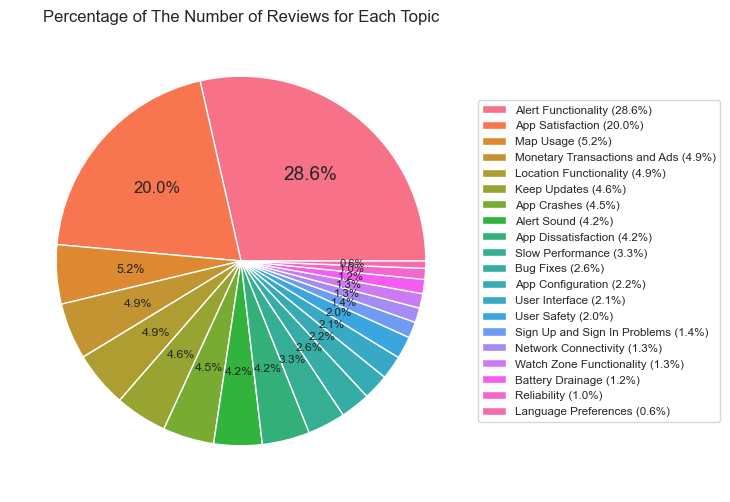

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate the percentage of total reviews for each topic ID
total_reviews = pie_data['Total_Reviews'].sum()
pie_data['Percentage'] = pie_data['Total_Reviews'] / total_reviews * 100

# Set the style of seaborn
sns.set_style("whitegrid")

# Create a pie chart
plt.figure(figsize=(10, 6))
patches, texts, autotexts = plt.pie(pie_data['Total_Reviews'], labels=None, autopct='%1.1f%%',
                                    colors=sns.color_palette("husl", len(pie_data)))

# Adjust the size of labels based on the percentage of total reviews
for autotext, percentage in zip(autotexts, pie_data['Percentage']):
    autotext.set_fontsize(8 + 0.2 * percentage)

# Add labels with Topic and percentage
plt.legend(pie_data['Topic'] + ' (' + pie_data['Percentage'].map('{:.1f}%'.format) + ')', 
           loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

# Add title
plt.title('Percentage of The Number of Reviews for Each Topic')

# plt.savefig('../output/perc_review_topic.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()


# 9. Geographical Analysis

/var/folders/yt/l0nw77zs49ngzv8jdxrtpfbh0000gn/T/ipykernel_3551/2709873884.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Geographic Coverage', y='Total Apps', palette='viridis')


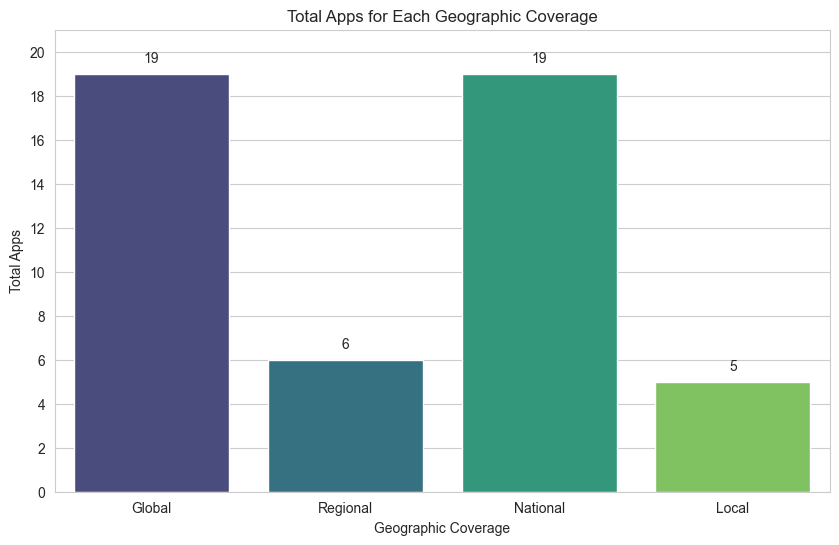

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Data
data = {
    'Geographic Coverage': ['Global', 'Regional', 'National', 'Local'],
    'Total Apps': [19, 6, 19, 5]
}

# Convert data to DataFrame
df = pd.DataFrame(data)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Geographic Coverage', y='Total Apps', palette='viridis')
plt.xlabel('Geographic Coverage')
plt.ylabel('Total Apps')

# Adding labels on top of each bar
for index, row in df.iterrows():
    plt.text(index, row['Total Apps']+0.5, str(row['Total Apps']), ha='center')

# Set y-axis ticks to integer values
plt.yticks(range(0, max(df['Total Apps'])+2, 2))

# Adjust ylim to accommodate the extra space needed for labels
plt.ylim(0, max(df['Total Apps']) + 2)

plt.title('Total Apps for Each Geographic Coverage')

#plt.savefig('../output/geographic_coverage.png', dpi=300, bbox_inches='tight')

plt.show()


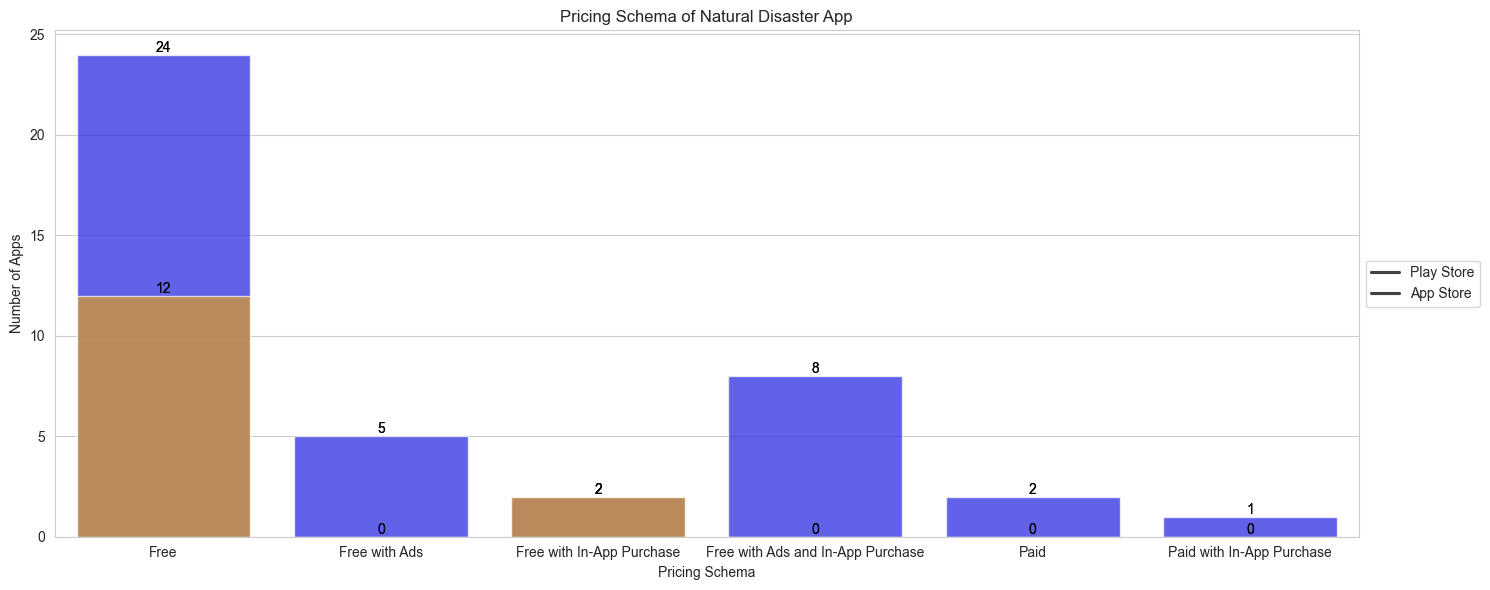

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Data
data_play_store = {
    'Pricing Schema': ['Free', 'Free with Ads', 'Free with In-App Purchase', 'Free with Ads and In-App Purchase', 'Paid', 'Paid with In-App Purchase'],
    'Play Store': [24, 5, 2, 8, 2, 1]
}

data_app_store = {
    'Pricing Schema': ['Free', 'Free with Ads', 'Free with In-App Purchase', 'Free with Ads and In-App Purchase', 'Paid', 'Paid with In-App Purchase'],
    'App Store': [12, 0, 2, 0, 0, 0]
}

# Convert data to DataFrame
df_play_store = pd.DataFrame(data_play_store)
df_app_store = pd.DataFrame(data_app_store)

# Merge the two dataframes
df = pd.concat([df_play_store, df_app_store.drop('Pricing Schema', axis=1)], axis=1)

# Create subplots
fig, ax = plt.subplots(figsize=(15, 6))

# Plot Play Store data with 'viridis' color palette
play_bars = sns.barplot(data=df, x='Pricing Schema', y='Play Store', ax=ax, color='blue', alpha=0.7)

# Plot App Store data with a single color
app_bars = sns.barplot(data=df, x='Pricing Schema', y='App Store', ax=ax, color='orange', alpha=0.7)

# Set labels
ax.set_xlabel('Pricing Schema')
ax.set_ylabel('Number of Apps')
ax.set_title('Pricing Schema of Natural Disaster App')

# Place the legend on the right side
ax.legend(labels=['Play Store', 'App Store'], loc='center left', bbox_to_anchor=(1, 0.5))

# Add counts inside each bar
for bar in play_bars.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), int(bar.get_height()), ha='center', va='bottom', color='black')

for bar in app_bars.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), int(bar.get_height()), ha='center', va='bottom', color='black')

# Adjust layout
plt.tight_layout()

# Show plot
plt.show()


/var/folders/yt/l0nw77zs49ngzv8jdxrtpfbh0000gn/T/ipykernel_3551/3573960747.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Disaster Type', y='Total Apps', palette='viridis')


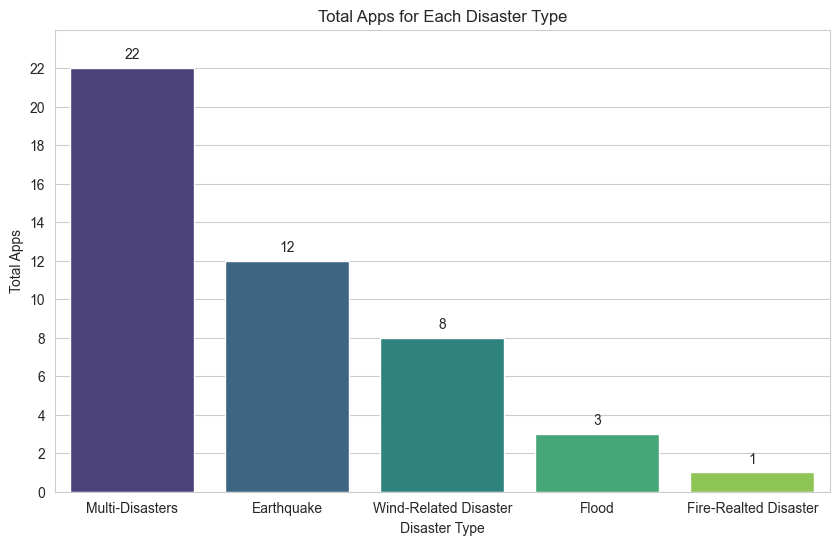

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Data for Total Apps for Each Disaster Type
data = {
    'Disaster Type': ['Multi-Disasters', 'Earthquake', 'Wind-Related Disaster', 'Flood', 'Fire-Realted Disaster'],
    'Total Apps': [22, 12, 8, 3, 1]
}

# Convert data to DataFrame
df = pd.DataFrame(data)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='Disaster Type', y='Total Apps', palette='viridis')
plt.xlabel('Disaster Type')
plt.ylabel('Total Apps')

# Adding labels on top of each bar
for index, row in df.iterrows():
    plt.text(index, row['Total Apps']+0.5, str(row['Total Apps']), ha='center')

# Set y-axis ticks to integer values
plt.yticks(range(0, max(df['Total Apps'])+2, 2))

# Adjust ylim to accommodate the extra space needed for labels
plt.ylim(0, max(df['Total Apps']) + 2)

plt.title('Total Apps for Each Disaster Type')

# plt.savefig('../output/disaster_type.png', dpi=300, bbox_inches='tight')
plt.show()
